# Fase 3 · Análisis exploratorio de datos (EDA)
**Proyecto:** Sistema de evaluación de riesgo crediticio · CrediAvanza  
**Datos:** `application_train.csv` (Home Credit Default Risk, Kaggle)

Reglas de este notebook: cada gráfico se explica **después de ejecutarlo** y las conclusiones se escriben con los números reales que aparezcan en tu pantalla.
Las celdas de texto *"Mis conclusiones"* están vacías a propósito: complétalas tú con lo que observes.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

# Raíz del proyecto (funciona si el notebook se ejecuta desde notebooks/ o desde la raíz)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
GRAF = RAIZ / "reports" / "graficos"
GRAF.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(RAIZ / "data" / "application_train.csv")
print(df.shape)
df.head()

(307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,...,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,...,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,...,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,...,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,...,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,...,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


## 1. Variable objetivo TARGET y desequilibrio de clases
Variable analizada: `TARGET` (0 = sin incumplimiento registrado, 1 = incumplimiento registrado, según la documentación).

        solicitudes  porcentaje
TARGET                         
0            282686       91.93
1             24825        8.07
Proporción 0:1 = 11.4 : 1


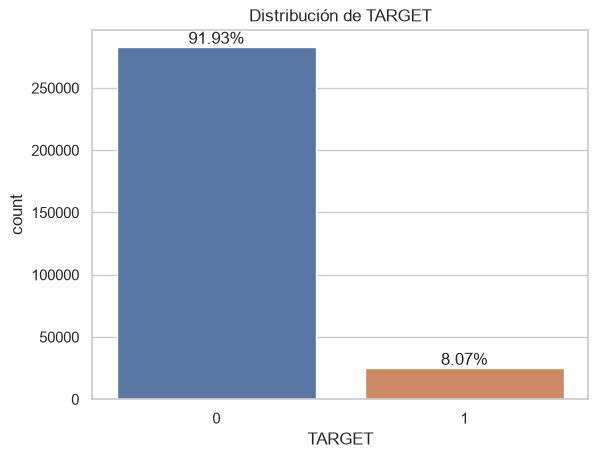

In [2]:
conteo = df["TARGET"].value_counts().sort_index()
porc = (conteo / len(df) * 100).round(2)
print(pd.DataFrame({"solicitudes": conteo, "porcentaje": porc}))
print(f"Proporción 0:1 = {conteo[0] / conteo[1]:.1f} : 1")

ax = sns.countplot(data=df, x="TARGET", hue="TARGET", legend=False)
for p, v in zip(ax.patches, porc):
    ax.annotate(f"{v}%", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Distribución de TARGET")
plt.savefig(GRAF / "eda_target.png", dpi=150, bbox_inches="tight")
plt.show()

**Qué mirar:** la altura relativa de las dos barras.  
**Por qué importa:** con clases tan desiguales, el *accuracy* engaña (predecir siempre 0 ya daría un accuracy muy alto). Usaremos recall, F1 y ROC-AUC.

**Mis conclusiones:** _(escribe aquí con tus números)_

## 2. Valores nulos

Columnas con nulos: 67 de 122
Columnas con más de 50 % de nulos: 41
                n_columnas  % nulos medio
Vivienda _AVG           14           58.4
Vivienda _MEDI          14           58.4
Vivienda _MODE          19           57.0
EXT_SOURCE               3           25.5
Otras                    7           14.0
Consultas buró           6           13.5
Círculo social           4            0.3


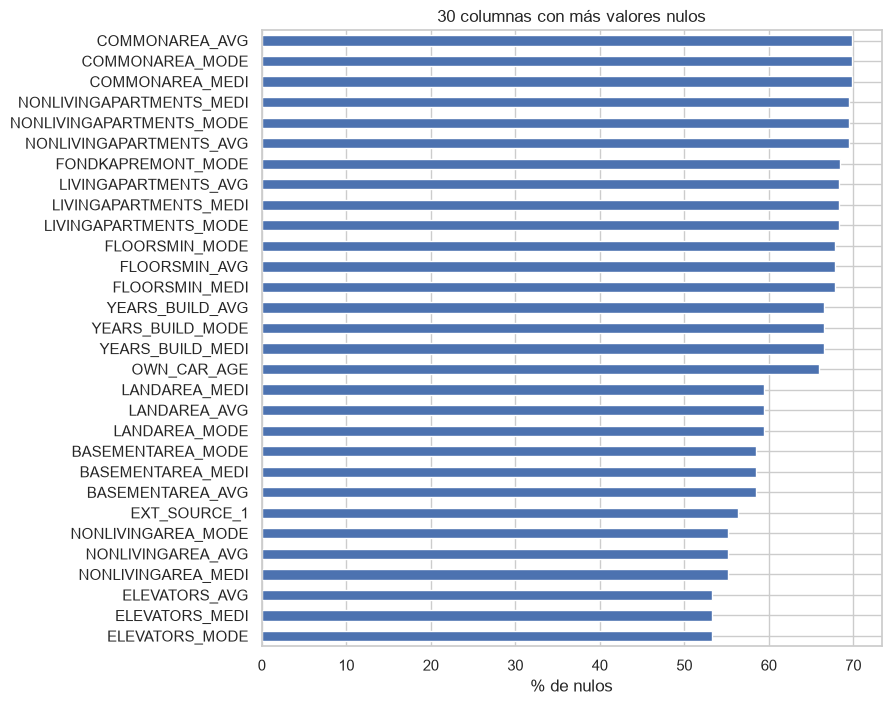

In [3]:
nulos = df.isna().mean().mul(100).sort_values(ascending=False)
nulos = nulos[nulos > 0]
print(f"Columnas con nulos: {len(nulos)} de {df.shape[1]}")
print(f"Columnas con más de 50 % de nulos: {(nulos > 50).sum()}")

def grupo(c):
    for sufijo in ("_AVG", "_MODE", "_MEDI"):
        if c.endswith(sufijo): return "Vivienda " + sufijo
    if c.startswith("EXT_SOURCE"): return "EXT_SOURCE"
    if c.startswith("AMT_REQ_CREDIT_BUREAU"): return "Consultas buró"
    if "SOCIAL_CIRCLE" in c: return "Círculo social"
    return "Otras"

resumen = nulos.groupby(nulos.index.map(grupo)).agg(["count", "mean"]).round(1)
resumen.columns = ["n_columnas", "% nulos medio"]
print(resumen.sort_values("% nulos medio", ascending=False))

nulos.head(30)[::-1].plot.barh(figsize=(8, 8))
plt.xlabel("% de nulos")
plt.title("30 columnas con más valores nulos")
plt.savefig(GRAF / "eda_nulos.png", dpi=150, bbox_inches="tight")
plt.show()

**Qué mirar:** qué grupos concentran los nulos y si los grupos `_AVG`, `_MODE`, `_MEDI` aparecen juntos.  
**Decisión que se discute:** no eliminar filas; imputar las variables elegidas y descartar el bloque de vivienda por redundancia y porcentaje de nulos (ver sección 8).

**Mis conclusiones:** _(escribe aquí)_

## 3. Variables de tiempo `DAYS_*` y valor anómalo en `DAYS_EMPLOYED`
La documentación indica que son días relativos a la fecha de solicitud (negativos). Aquí lo **comprobamos**.

       DAYS_BIRTH  DAYS_EMPLOYED
count    307511.0       307511.0
mean     -16037.0        63815.0
std        4364.0       141275.8
min      -25229.0       -17912.0
25%      -19682.0        -2760.0
50%      -15750.0        -1213.0
75%      -12413.0         -289.0
max       -7489.0       365243.0

Valor máximo de DAYS_EMPLOYED: 365243 (aparece 55,374 veces = 18.0 %)
Equivale a 1000.0 años: no es una antigüedad laboral real.

Tasa de TARGET=1 (%):
DAYS_EMPLOYED
empleo normal    8.66
valor anómalo    5.40
Name: TARGET, dtype: float64

Tipos de ingreso de las filas anómalas:
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64


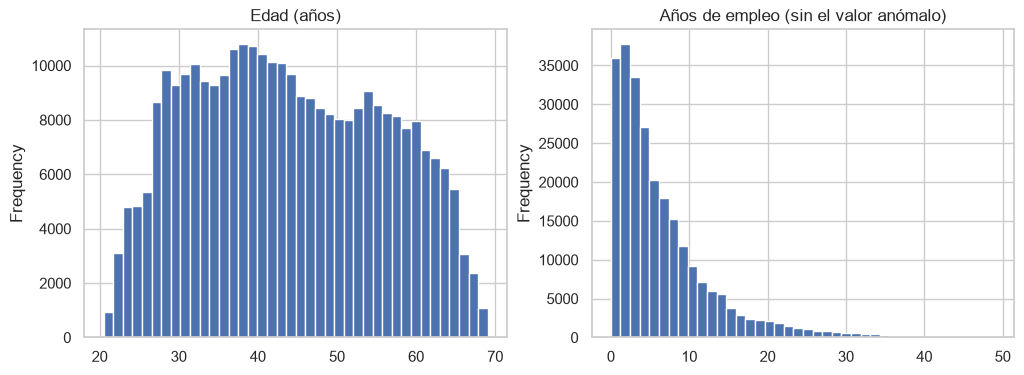

In [4]:
print(df[["DAYS_BIRTH", "DAYS_EMPLOYED"]].describe().round(1))

valor_max = df["DAYS_EMPLOYED"].max()
n_anom = (df["DAYS_EMPLOYED"] == valor_max).sum()
print(f"\nValor máximo de DAYS_EMPLOYED: {valor_max} (aparece {n_anom:,} veces = {n_anom/len(df)*100:.1f} %)")
print("Equivale a", round(valor_max / 365.25, 1), "años: no es una antigüedad laboral real.")

anom = df["DAYS_EMPLOYED"] == valor_max
print("\nTasa de TARGET=1 (%):")
print(df.groupby(anom)["TARGET"].mean().mul(100).round(2).rename({False: "empleo normal", True: "valor anómalo"}))
print("\nTipos de ingreso de las filas anómalas:")
print(df.loc[anom, "NAME_INCOME_TYPE"].value_counts().head())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
(-df["DAYS_BIRTH"] / 365.25).plot.hist(bins=40, ax=ax[0])
ax[0].set_title("Edad (años)")
(-df.loc[~anom, "DAYS_EMPLOYED"] / 365.25).plot.hist(bins=40, ax=ax[1])
ax[1].set_title("Años de empleo (sin el valor anómalo)")
plt.savefig(GRAF / "eda_edad_empleo.png", dpi=150, bbox_inches="tight")
plt.show()

**Qué mirar:** si el valor máximo se repite miles de veces y a qué tipo de ingreso corresponde.  
**Decisión:** si se confirma, tratarlo como valor centinela: se convierte en nulo y se conserva un indicador `EMPLEO_ANOMALO` (ya implementado en `src/limpieza.py`).

**Mis conclusiones:** _(escribe aquí)_

## 4. Valores extremos (outliers) en importes

       AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  AMT_GOODS_PRICE
count          307511.0    307511.0     307499.0         307233.0
mean           168798.0    599026.0      27109.0         538396.0
std            237123.0    402491.0      14494.0         369446.0
min             25650.0     45000.0       1616.0          40500.0
1%              45000.0     76410.0       6183.0          67500.0
50%            147150.0    513531.0      24903.0         450000.0
99%            472500.0   1854000.0      70006.0        1800000.0
max         117000000.0   4050000.0     258026.0        4050000.0
AMT_INCOME_TOTAL: 14,035 valores por encima de Q3 + 1.5·IQR (337,500)
AMT_CREDIT: 6,562 valores por encima de Q3 + 1.5·IQR (1,616,625)
AMT_ANNUITY: 7,504 valores por encima de Q3 + 1.5·IQR (61,704)
AMT_GOODS_PRICE: 14,728 valores por encima de Q3 + 1.5·IQR (1,341,000)


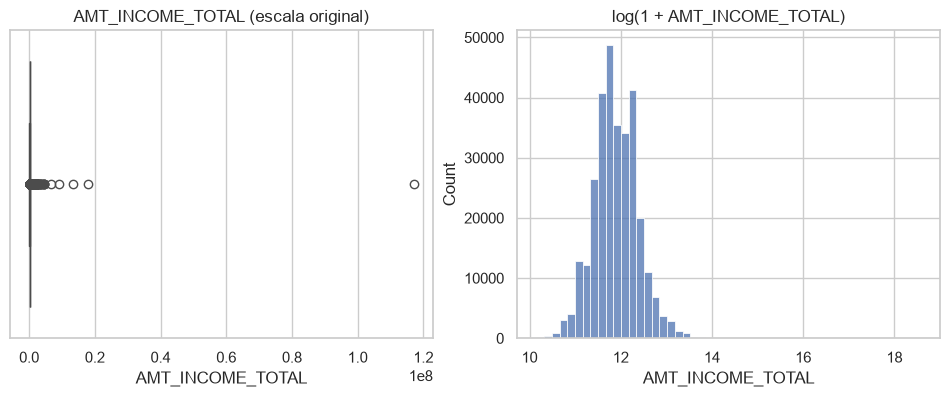

In [5]:
cols = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]
print(df[cols].describe(percentiles=[.01, .5, .99]).round(0))

for c in cols:
    q1, q3 = df[c].quantile([.25, .75])
    lim = q3 + 1.5 * (q3 - q1)
    print(f"{c}: {(df[c] > lim).sum():,} valores por encima de Q3 + 1.5·IQR ({lim:,.0f})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["AMT_INCOME_TOTAL"], ax=ax[0]); ax[0].set_title("AMT_INCOME_TOTAL (escala original)")
sns.histplot(np.log1p(df["AMT_INCOME_TOTAL"]), bins=50, ax=ax[1]); ax[1].set_title("log(1 + AMT_INCOME_TOTAL)")
plt.savefig(GRAF / "eda_outliers_ingreso.png", dpi=150, bbox_inches="tight")
plt.show()

**Qué mirar:** la distancia entre el percentil 99 y el máximo, y la forma tras el logaritmo.  
**Decisión:** no se eliminan filas; se aplica logaritmo a los importes para reducir el efecto de los extremos (sobre todo importante para KNN).

**Mis conclusiones:** _(escribe aquí)_

## 5. Variables categóricas y tasa de incumplimiento
Atención: una tasa distinta entre categorías indica **asociación**, no causalidad. Fíjate también en cuántas solicitudes tiene cada categoría.


NAME_INCOME_TYPE
                       % TARGET=1       n
NAME_INCOME_TYPE                        
Commercial associate        7.48   71617
Working                     9.59  158774
Unemployed                 36.36      22
Maternity leave            40.00       5

NAME_EDUCATION_TYPE
                                % TARGET=1       n
NAME_EDUCATION_TYPE                              
Higher education                     5.36   74863
Incomplete higher                    8.48   10277
Secondary / secondary special        8.94  218391
Lower secondary                     10.93    3816

NAME_FAMILY_STATUS
                       % TARGET=1       n
NAME_FAMILY_STATUS                      
Married                     7.56  196432
Separated                   8.19   19770
Single / not married        9.81   45444
Civil marriage              9.94   29775

NAME_HOUSING_TYPE
                      % TARGET=1      n
NAME_HOUSING_TYPE                     
Co-op apartment            7.93   1122
Municipal

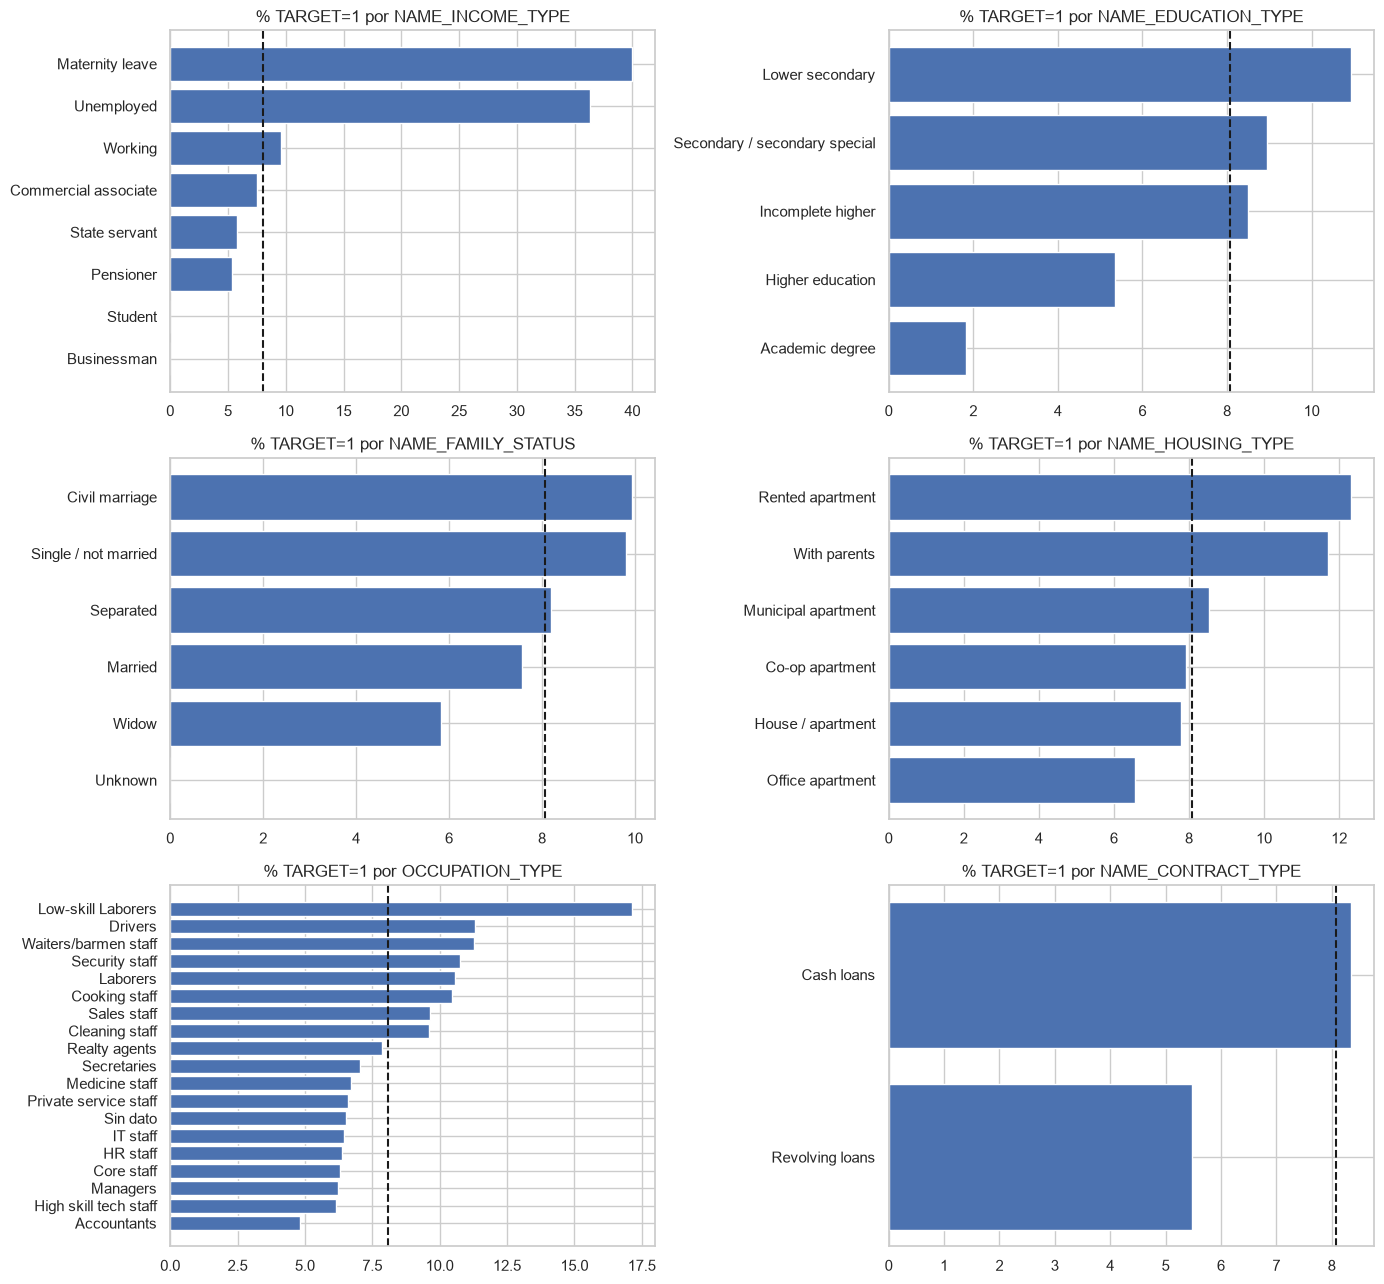

In [6]:
vars_cat = ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE", "OCCUPATION_TYPE", "NAME_CONTRACT_TYPE"]
tasa_global = df["TARGET"].mean() * 100
fig, ejes = plt.subplots(3, 2, figsize=(14, 13))
for ax, c in zip(ejes.ravel(), vars_cat):
    t = df.assign(**{c: df[c].fillna("Sin dato")}).groupby(c)["TARGET"].agg(["mean", "count"])
    t["mean"] *= 100
    t = t.sort_values("mean")
    ax.barh(t.index, t["mean"])
    ax.axvline(tasa_global, color="k", ls="--")
    ax.set_title(f"% TARGET=1 por {c}")
    print(f"\n{c}\n", t.rename(columns={"mean": "% TARGET=1", "count": "n"}).round(2).tail(4))
plt.tight_layout()
plt.savefig(GRAF / "eda_categoricas.png", dpi=150, bbox_inches="tight")
plt.show()

**Qué mirar:** categorías por encima/debajo de la línea discontinua (tasa global) con un número suficiente de solicitudes.

**Mis conclusiones:** _(escribe aquí; evita frases causales)_

## 6. Correlaciones con TARGET
La correlación de Pearson con una variable binaria es una pista sencilla, no una medida completa de capacidad predictiva.

EXT_SOURCE_3                  -0.1789
EXT_SOURCE_2                  -0.1605
EXT_SOURCE_1                  -0.1553
DAYS_EMPLOYED                 -0.0449
FLOORSMAX_AVG                 -0.0440
FLOORSMAX_MEDI                -0.0438
FLOORSMAX_MODE                -0.0432
AMT_GOODS_PRICE               -0.0396
REGION_POPULATION_RELATIVE    -0.0372
ELEVATORS_AVG                 -0.0342
DAYS_REGISTRATION              0.0420
FLAG_DOCUMENT_3                0.0443
REG_CITY_NOT_LIVE_CITY         0.0444
FLAG_EMP_PHONE                 0.0460
REG_CITY_NOT_WORK_CITY         0.0510
DAYS_ID_PUBLISH                0.0515
DAYS_LAST_PHONE_CHANGE         0.0552
REGION_RATING_CLIENT           0.0589
REGION_RATING_CLIENT_W_CITY    0.0609
DAYS_BIRTH                     0.0782
Name: TARGET, dtype: float64


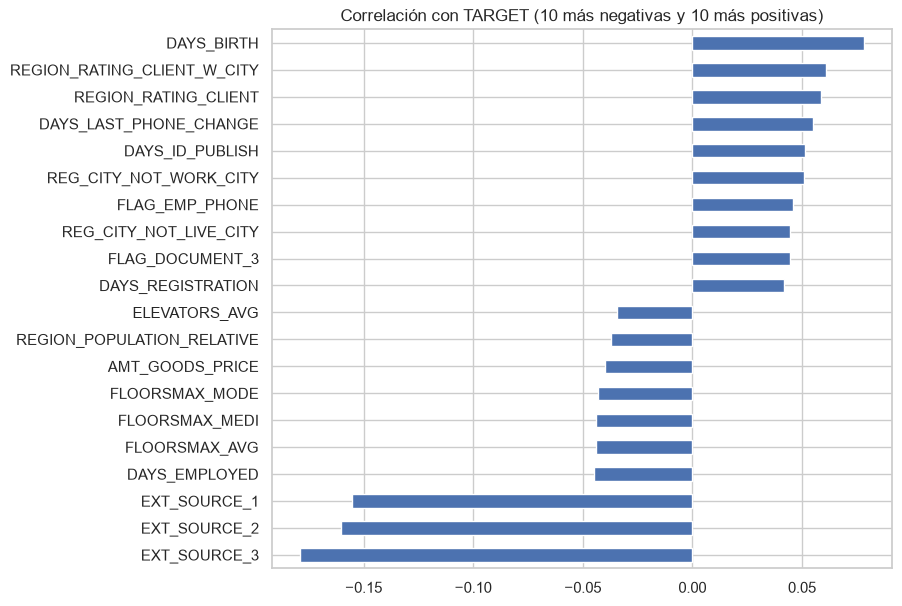

In [7]:
corr = df.corr(numeric_only=True)["TARGET"].drop(["TARGET", "SK_ID_CURR"]).sort_values()
top = pd.concat([corr.head(10), corr.tail(10)])
print(top.round(4))
top.plot.barh(figsize=(8, 7))
plt.title("Correlación con TARGET (10 más negativas y 10 más positivas)")
plt.savefig(GRAF / "eda_correlacion_target.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, c in enumerate(["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]):
    sns.kdeplot(data=df.dropna(subset=[c]), x=c, hue="TARGET", common_norm=False, ax=ax[i])
    ax[i].set_title(c)
plt.savefig(GRAF / "eda_ext_source.png", dpi=150, bbox_inches="tight")
plt.show()

**Qué mirar:** si las curvas de TARGET=0 y TARGET=1 se separan. `EXT_SOURCE_*` son puntuaciones de fuentes externas (la documentación no detalla cómo se calculan): predicen, pero no sabemos *por qué*.

**Mis conclusiones:** _(escribe aquí)_

## 7. Correlación entre las variables numéricas candidatas

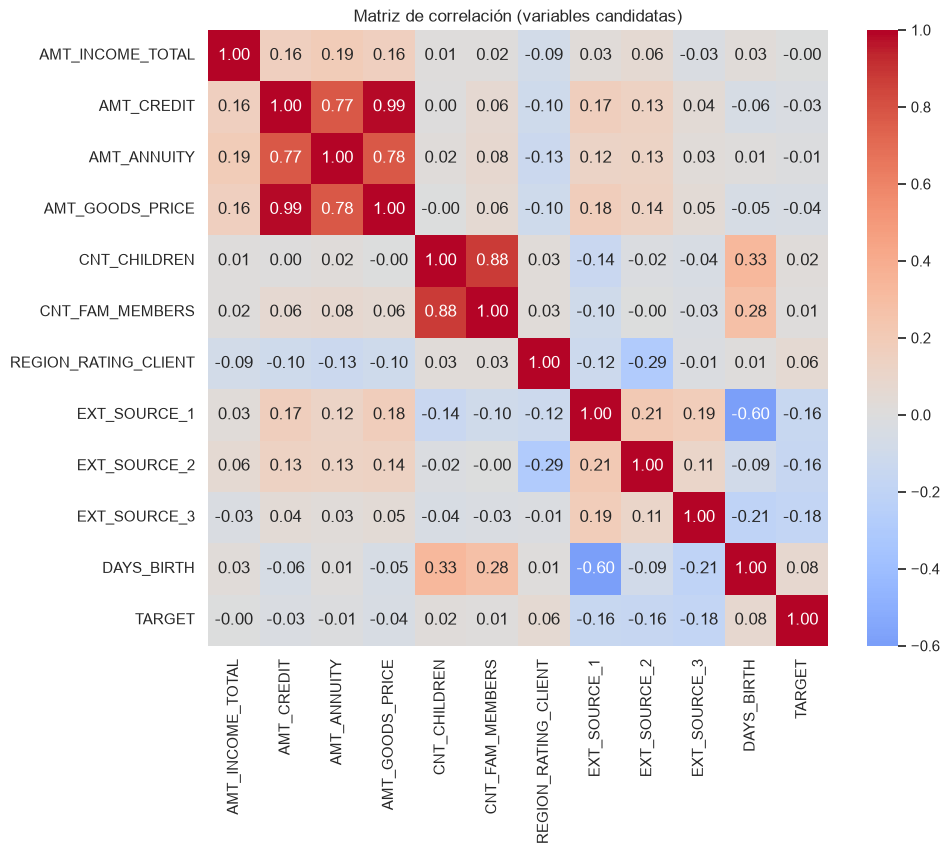

In [9]:
candidatas = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE", "CNT_CHILDREN", "CNT_FAM_MEMBERS",
              "REGION_RATING_CLIENT", "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "DAYS_BIRTH", "TARGET"]
plt.figure(figsize=(10, 8))
sns.heatmap(df[candidatas].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación (variables candidatas)")
plt.savefig(GRAF / "eda_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Qué mirar:** pares con correlación muy alta (p. ej. importe del crédito, precio de los bienes y cuota). Variables muy correlacionadas aportan información repetida; no es un problema grave para árboles, pero sí para interpretar.

**Mis conclusiones:** _(escribe aquí)_

## 8. Justificación de descartar el bloque de vivienda `_AVG` / `_MODE` / `_MEDI`

In [10]:
print(df[["APARTMENTS_AVG", "APARTMENTS_MODE", "APARTMENTS_MEDI"]].corr().round(3))
bloque = [c for c in df.columns if c.endswith(("_AVG", "_MODE", "_MEDI"))]
print(f"\nColumnas del bloque: {len(bloque)} | % medio de nulos: {df[bloque].isna().mean().mean()*100:.1f}")
num_bloque = df[bloque].select_dtypes("number").columns
print("Máxima correlación absoluta con TARGET en el bloque numérico:",
      df[list(num_bloque) + ["TARGET"]].corr()["TARGET"].drop("TARGET").abs().max().round(4))

                 APARTMENTS_AVG  APARTMENTS_MODE  APARTMENTS_MEDI
APARTMENTS_AVG            1.000            0.973            0.995
APARTMENTS_MODE           0.973            1.000            0.977
APARTMENTS_MEDI           0.995            0.977            1.000

Columnas del bloque: 47 | % medio de nulos: 57.9
Máxima correlación absoluta con TARGET en el bloque numérico: 0.044


**Mis conclusiones:** _(si las tres versiones están casi perfectamente correlacionadas y el bloque tiene muchos nulos y poca correlación con TARGET, descartarlo queda justificado con datos)_

---
### Resumen final del EDA
Completa aquí 5-6 hallazgos con números reales: desequilibrio, nulos, valor anómalo de `DAYS_EMPLOYED`, outliers de importes, variables con mayor asociación a TARGET y variables descartadas.